In [1]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
from tensorflow.keras import Model,Layer
from tensorflow.keras.layers import Dense
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')


import matplotlib.pyplot as plt
import numpy as np
import h5py
import math
import sionna

# Load the required Sionna components
from sionna.phy import Block
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder, EXITCallback
from sionna.phy.fec.interleaving import RandomInterleaver, Deinterleaver
from sionna.phy.fec.scrambling import Scrambler, Descrambler
from sionna.phy.fec.utils import GaussianPriorSource, load_parity_check_examples, \
                                 get_exit_analytic, plot_exit_chart, plot_trajectory
from sionna.phy.utils import ebnodb2no, hard_decisions, PlotBER, split_dim, expand_to_rank
from sionna.phy.channel import AWGN

from scipy.sparse import csr_matrix

sionna.phy.config.seed = 42 # Set seed for reproducible random number generation


E0000 00:00:1787816855.206755    4388 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1787816855.220380    4388 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1787816855.321774    4388 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1787816855.321805    4388 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1787816855.321807    4388 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1787816855.321809    4388 computation_placer.cc:177] computation placer already registered. Please check linka

In [2]:
import sionna as sn

In [3]:
from custom_classes_shaping import Demapper_optimized

from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder

In [4]:

# print(gpus)

# import importlib
# import custom_classes_shaping
# importlib.reload(custom_classes_shaping)


# from custom_classes_shaping import Demapper_optimized, Shaping_encoder_neural, Shaping_decoder_forward, \
#     Shaping_decoder_backward, Demodulator_bitwise, Modulator, shaping_encoder_func, shaping_encoder_func_adjusted, Shaping_encoder_neural,\
#     Shaping_dec_forward_neural, Shaping_dec_backward_neural, Shaping_encoder, Pilot_RBF, Ch_est_equalize, Demodulator_bitwise_awgn, Ch_est_equalize_corrected
import pickle

# import ccdm
from ccdm_initialize import initialize
import time


In [37]:


# APSK 32 points

symbol_points_apsk = [0.192425859850790 + 0.192425859850790j,
0.693946738059284 + 0.185942468053197j,
0.192425859850790 - 0.192425859850790j,
0.693946738059283 - 0.185942468053197j,
-0.192425859850790 + 0.192425859850790j,
-0.693946738059284 + 0.185942468053197j,
-0.192425859850790 - 0.192425859850790j,
-0.693946738059284 - 0.185942468053197j,
0.185942468053197 + 0.693946738059283j,
0.508004270006087 + 0.508004270006087j,
0.185942468053197 - 0.693946738059284j,
0.508004270006087 - 0.508004270006087j,
-0.185942468053197 + 0.693946738059284j,
-0.508004270006087 + 0.508004270006087j,
-0.185942468053197 - 0.693946738059283j,
-0.508004270006087 - 0.508004270006087j,
0.892855989707667 + 0.892855989707667j,
1.26268904989064 + 0.00000000000000j,
0.483210179621963 - 1.16657256912008j,
1.16657256912008 - 0.483210179621963j,
-0.483210179621963 + 1.16657256912008j,
-1.16657256912008 + 0.483210179621963j,
-0.892855989707668 - 0.892855989707667j,
-1.26268904989064 + 1.54634810326698e-16j,
0.483210179621963 + 1.16657256912008j,
1.16657256912008 + 0.483210179621963j,
-2.31952215490047e-16 - 1.26268904989064j,
0.892855989707667 - 0.892855989707668j,
7.73174051633490e-17 + 1.26268904989064j,
-0.892855989707667 + 0.892855989707667j,
-0.483210179621963 - 1.16657256912008j,
-1.16657256912008 - 0.483210179621962j]

learned_awgn_points = np.load("adjusted_32point_const_points.npy")


In [38]:

def generate_ldpc_H_matrix(n_ldpc: int, rate: float, q: int, file_path: str) -> np.ndarray:
    # Compute derived parameters
    k_ldpc = int(n_ldpc * rate)
    N_p = n_ldpc - k_ldpc  # number of parity bits

    data = []
    with open(file_path, "r") as file:
        for line in file:
            values = [int(v) for v in line.strip().split()]
            data.append(values)

    H_matrix = np.zeros((N_p, n_ldpc), dtype=np.uint8)

    for index, base_addresses in enumerate(data):
        base_addresses = np.array(base_addresses)

        for addr in base_addresses:
            H_matrix[addr, 360 * index + 0] = 1

        for m in range(1, 360):
            for addr in base_addresses:
                new_addr = (addr + (m % 360) * q) % N_p
                H_matrix[new_addr, 360 * index + m] = 1

    P_matrix = np.zeros((N_p, N_p), dtype=int)
    np.fill_diagonal(P_matrix, 1)
    for i in range(1, N_p):
        P_matrix[i, i - 1] = 1

    H_matrix[:, k_ldpc:] = P_matrix

    return H_matrix

In [44]:
class BICM_scheme_awgn(Model):

    def __init__(self, batch_size, num_bp_iter, use_dvb, symbol_points, perfect_csi, use_RBF):
        super().__init__() # Must call the Keras model initializer

        self.use_dvb = use_dvb
        self.use_RBF = use_RBF
        self.batch_size = batch_size
        llr_max_value = 120.00

        self.channel = AWGN()
        self.num_bits_per_symbol = 5

        if self.use_dvb:

            r = 2/3
            n_ldpc = 16200
            self.n = n_ldpc
            self.k = int(n_ldpc*r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k])

            self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False)
            self.source = BinarySource()

        else:
            self.k = 864
            self.n = 1440

            self.binary_source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            # self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        if self.use_RBF:
            self.RBF_blocksize = 16
            pilot_symbol = 1.0+0.0j
            K_factor = 10 # Adjustable K (0=Rayleigh, inf=AWGN/LoS)
            self.pilot_rbf = Pilot_RBF(self.RBF_blocksize, pilot_symbol, K_factor)
            self.ch_est_equalize = Ch_est_equalize_corrected(self.pilot_rbf, perfect_csi)

        probabilities = np.ones_like(symbol_points)/(2**self.num_bits_per_symbol)

        power = np.sum(probabilities * np.abs(symbol_points)**2)
        normalized_points = symbol_points / np.sqrt(power)

        constellation = Constellation("custom", num_bits_per_symbol=self.num_bits_per_symbol , points = normalized_points)

        # mapper and demapper
        self.mapper = Mapper(constellation=constellation)

        self.demapper = Demapper("app", constellation=constellation) # APP demapper

        self.num_symbols = int(self.n/self.num_bits_per_symbol)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        # calculate noise variance
        if self.use_RBF:
            no = ebnodb2no(ebno_db,
                           num_bits_per_symbol=self.num_bits_per_symbol*(1-1/(self.RBF_blocksize+1)),
                           coderate=3/5)
        else:
            # no = ebnodb2no(ebno_db,
            #    num_bits_per_symbol=self.num_bits_per_symbol,
            #    coderate=8/15)

            #### Adding this to compute with esno ####
            no = ebnodb2no(ebno_db,
               num_bits_per_symbol=1,
               coderate=1)

        if self.use_dvb:
            # u, c = next(self.iterator)
            b_stream = tf.cast(self.source([batch_size, self.k]),tf.int32) # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            c = tf.concat([b_stream, p_bits], axis=1)
        else:
            u = self.binary_source([self.batch_size, self.k])
            c = tf.cast(self.encoder(u),tf.uint8)

        # u, c = next(self.iterator)
        c_int = self.interleaver(c)
        x = self.mapper(c_int)

        ##################################
        if self.use_RBF:
            x_mod_pilots, h_exact = self.pilot_rbf(x, batch_size = self.batch_size)
            # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
            # print('meansquare',mean_squared.numpy())
            y = self.channel(x_mod_pilots, no) # transmit over AWGN channel
            # y = self.channel(x, no) # transmit over AWGN channel
            # print(y.shape)
            # print(no.shape)
            # print(h_exact.shape)

            y_equalized, h_hat, rho, epsilon2 = self.ch_est_equalize(y, no, h_exact)
            y_for_demap = y_equalized / tf.cast(rho,tf.complex64)
            sigma2_eff = epsilon2 / tf.square(tf.abs(rho))
            llr_ch = self.demapper(y_for_demap, sigma2_eff)
            # print('y_equalized :',y_equalized.shape)
            # print('rho :',rho.shape)
            # print('epsilon2 :',epsilon2.shape)
            # print('no :',no.shape)

            # llr_ch = self.demapper(y_equalized, no) # demapp
            # llr_ch = self.demapper(y, no) # demapp
        else:
            y = self.channel(x, no) # transmit over AWGN channel
            llr_ch = self.demapper(y, no) # demapp
        ##################################


        llr_deint = self.deinterleaver(llr_ch)


        # u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
        # b_stream_hat = u_stream_hat[:,:self.k]

        # return u, b_stream_hat


        if self.use_dvb:
            llr_u_stream = self.decoder(llr_deint)
            u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
            b_stream_hat = u_stream_hat[:,:self.k]
            return b_stream, b_stream_hat
        else:
            b_stream_hat = self.decoder(llr_deint) # run LDPC decoder
            return u, b_stream_hat


In [40]:
ber_plot_bicm_short = PlotBER("BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.0 | 1.9874e-01 | 1.0000e+00 |       42927 |      216000 |           20 |          20 |         0.1 |reached target bit errors
     6.16 | 1.9705e-01 | 1.0000e+00 |       42562 |      216000 |           20 |          20 |         0.1 |reached target bit errors
     6.32 | 1.9283e-01 | 1.0000e+00 |       41651 |      216000 |           20 |          20 |         0.1 |reached target bit errors
     6.48 | 1.8817e-01 | 1.0000e+00 |       40644 |      216000 |           20 |          20 |         0.1 |reached target bit errors
     6.64 | 1.8543e-01 | 1.0000e+00 |       40053 |      216000 |           20 |          20 |         0.1 |reached target bit errors
      6.8 | 1.8069e-01 | 1.0000e+00 |       39028 |      216000 |          

(<tf.Tensor: shape=(44,), dtype=float32, numpy=
 array([1.98736116e-01, 1.97046295e-01, 1.92828700e-01, 1.88166663e-01,
        1.85430557e-01, 1.80685192e-01, 1.78731486e-01, 1.75310180e-01,
        1.71800926e-01, 1.67902783e-01, 1.65064812e-01, 1.59046292e-01,
        1.57587960e-01, 1.53171301e-01, 1.49129629e-01, 1.44875005e-01,
        1.41884252e-01, 1.38189808e-01, 1.33421302e-01, 1.28444448e-01,
        1.25398144e-01, 1.19333334e-01, 1.14347219e-01, 1.09689817e-01,
        1.04861110e-01, 9.89351869e-02, 9.51018482e-02, 8.93101841e-02,
        8.30370337e-02, 7.36805573e-02, 6.54490739e-02, 5.63796312e-02,
        4.28796299e-02, 2.90023144e-02, 9.46296286e-03, 1.79754279e-03,
        1.06203704e-04, 2.77777787e-07, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       dtype=float32)>,
 <tf.Tensor: shape=(44,), dtype=float32, numpy=
 array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+

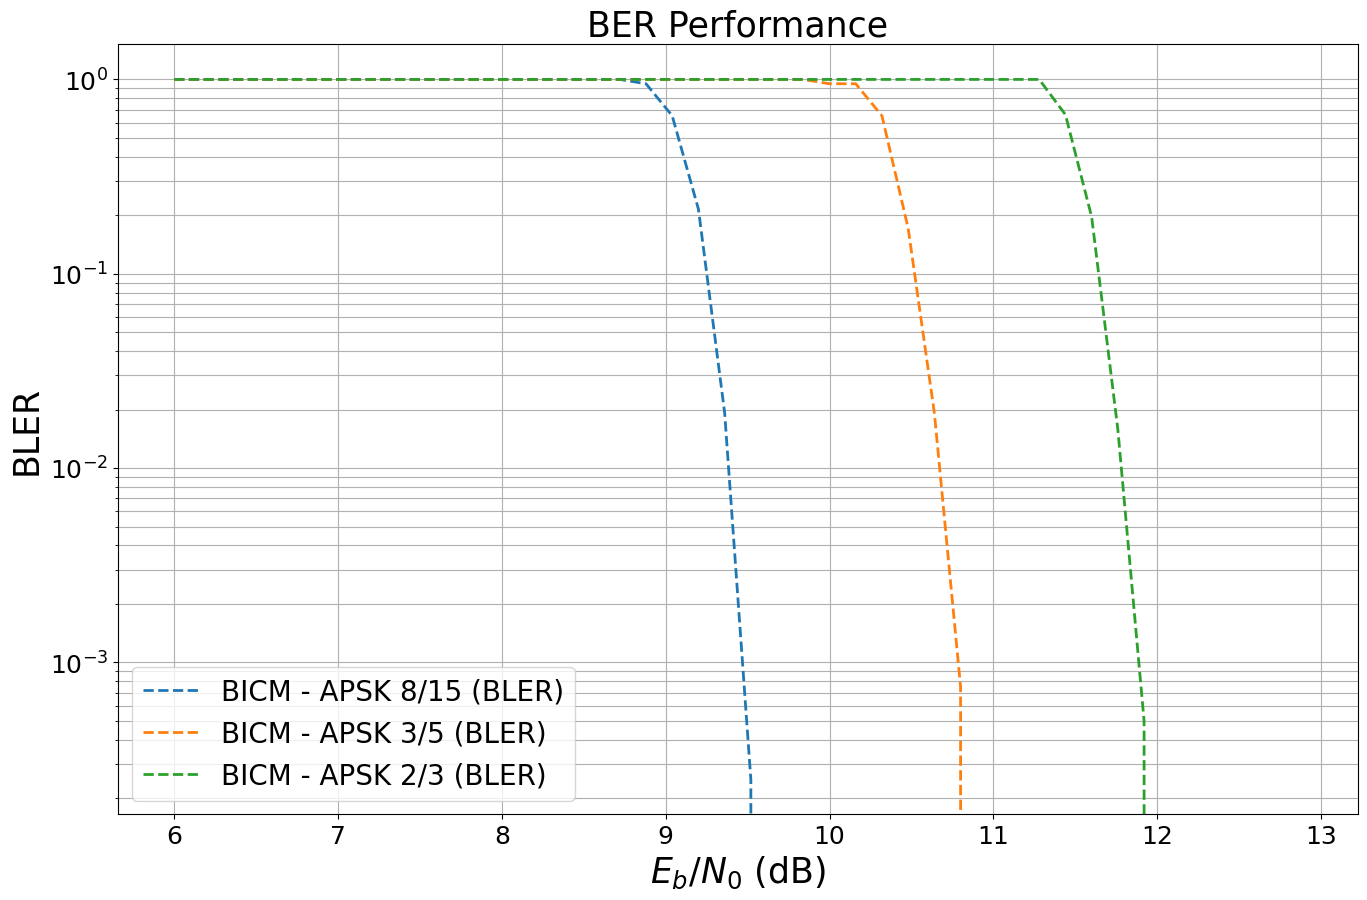

In [45]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_RBF = False
model_bicm = BICM_scheme_awgn(batch_size, num_bp_iter, use_dvb, symbol_points_apsk, perfect_csi, use_RBF)

u, u_hat = model_bicm(tf.constant(batch_size, tf.int32), tf.constant(5, tf.float32))



ber_plot_bicm_short.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(6, 13, 0.16),
                          legend="BICM - APSK 2/3",
                          add_bler = True,
                          add_ber = False,
                          max_mc_iter=200,
                          num_target_bit_errors=10000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)


In [47]:
ber_8_15 = ber_plot_bicm_short.ber[0]
ber_3_5 = ber_plot_bicm_short.ber[1]
ber_2_3 = ber_plot_bicm_short.ber[2]

snr_8_15 = ber_plot_bicm_short.snr[0]
snr_3_5 = ber_plot_bicm_short.snr[1]
snr_2_3 = ber_plot_bicm_short.snr[2]

R = np.array([8/15, 3/5, 2/3])*5

shannon_esn0_db = 10 * np.log10(2**R - 1)

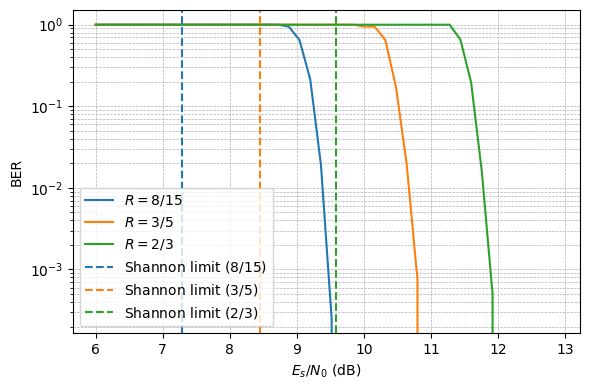

In [48]:

# Plot BER vs Es/N0
plt.figure(figsize=(6, 4))

plt.semilogy(snr_8_15, ber_8_15, label=r'$R=8/15$')
plt.semilogy(snr_3_5,  ber_3_5,  label=r'$R=3/5$')
plt.semilogy(snr_2_3,  ber_2_3,  label=r'$R=2/3$')

# Shannon limits as vertical dashed lines
colors = ['C0', 'C1', 'C2']
rate_labels = [r'$8/15$', r'$3/5$', r'$2/3$']

for i in range(3):
    plt.axvline(
        shannon_esn0_db[i],
        color=colors[i],
        linestyle='--',
        linewidth=1.5,
        label=f'Shannon limit ({rate_labels[i]})'
    )

plt.xlabel(r'$E_s/N_0$ (dB)')
plt.ylabel('BER')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.tight_layout()

plt.savefig('ber_vs_esn0_with_shannon.png', dpi=300)
plt.show()

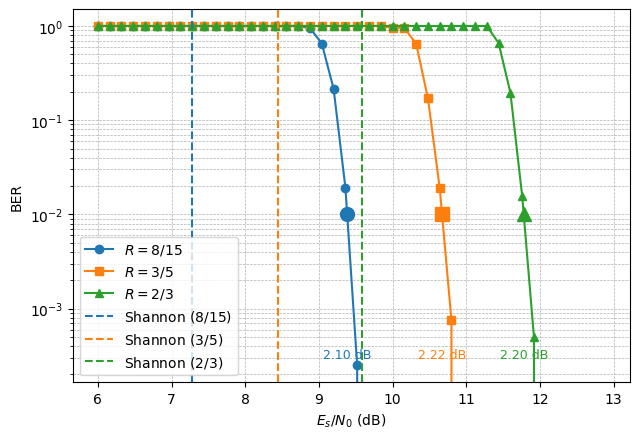

In [50]:
def esn0_at_ber(snr_db, ber, target_ber=1e-2):
    # 1. Remove zero-BER points
    mask = ber > 0
    snr_pos = snr_db[mask]
    ber_pos = ber[mask]

    # 2. Work in log10(BER)
    log_ber = np.log10(ber_pos)
    target_log_ber = np.log10(target_ber)

    # 3. Sort by log_ber (increasing) because np.interp requires increasing xp
    order = np.argsort(log_ber)
    xp = log_ber[order]
    fp = snr_pos[order]

    # 4. Interpolate
    return np.interp(target_log_ber, xp, fp)

# Your data
ber_8_15 = ber_plot_bicm_short.ber[0]
ber_3_5  = ber_plot_bicm_short.ber[1]
ber_2_3  = ber_plot_bicm_short.ber[2]

snr_8_15 = ber_plot_bicm_short.snr[0]
snr_3_5  = ber_plot_bicm_short.snr[1]
snr_2_3  = ber_plot_bicm_short.snr[2]

# Es/N0 at BER = 1e-3
esn0_8_15_at_1e4 = esn0_at_ber(snr_8_15, ber_8_15, 1e-2)
esn0_3_5_at_1e4  = esn0_at_ber(snr_3_5,  ber_3_5,  1e-2)
esn0_2_3_at_1e4  = esn0_at_ber(snr_2_3,  ber_2_3,  1e-2)

esn0_at_1e4_db = np.array([esn0_8_15_at_1e4, esn0_3_5_at_1e4, esn0_2_3_at_1e4])

# Shannon limits
R = np.array([8/15, 3/5, 2/3]) * 5
shannon_esn0_db = 10 * np.log10(2**R - 1)

# Plot
plt.figure(figsize=(6.5, 4.5))

plt.semilogy(snr_8_15, ber_8_15, 'o-', label=r'$R=8/15$')
plt.semilogy(snr_3_5,  ber_3_5,  's-', label=r'$R=3/5$')
plt.semilogy(snr_2_3,  ber_2_3,  '^-', label=r'$R=2/3$')

# Interpolation points at BER=1e-2
plt.plot(esn0_8_15_at_1e4, 1e-2, 'o', color='C0', markersize=10)
plt.plot(esn0_3_5_at_1e4,  1e-2, 's', color='C1', markersize=10)
plt.plot(esn0_2_3_at_1e4,  1e-2, '^', color='C2', markersize=10)

# Shannon limits (vertical dashed lines)
colors = ['C0', 'C1', 'C2']
rate_labels = [r'$8/15$', r'$3/5$', r'$2/3$']

for i in range(3):
    plt.axvline(shannon_esn0_db[i], color=colors[i], linestyle='--', linewidth=1.5,
                label=f'Shannon ({rate_labels[i]})')
    # Annotate gap
    gap = esn0_at_1e4_db[i] - shannon_esn0_db[i]
    plt.text(esn0_at_1e4_db[i], 3e-4, f'{gap:.2f} dB',
             color=colors[i], ha='center', fontsize=9)

plt.xlabel(r'$E_s/N_0$ (dB)')
plt.ylabel('BER')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('ber_vs_esn0_with_interp_points.png', dpi=300)
plt.show()

In [7]:
ber_plot_bicm = PlotBER("BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      3.6 | 1.5460e-01 | 1.0000e+00 |       26715 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.76 | 1.4963e-01 | 1.0000e+00 |       25856 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.92 | 1.4542e-01 | 1.0000e+00 |       25128 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     4.08 | 1.3950e-01 | 1.0000e+00 |       24105 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     4.24 | 1.3538e-01 | 1.0000e+00 |       23394 |      172800 |           20 |          20 |         0.1 |reached target bit errors
      4.4 | 1.2551e-01 | 1.0000e+00 |       21688 |      172800 |          

(<tf.Tensor: shape=(17,), dtype=float32, numpy=
 array([1.54600695e-01, 1.49629623e-01, 1.45416662e-01, 1.39496535e-01,
        1.35381937e-01, 1.25509262e-01, 1.15283564e-01, 6.46585673e-02,
        1.63194444e-02, 1.56766141e-03, 5.13310188e-05, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(17,), dtype=float32, numpy=
 array([1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 0.75      , 0.4       , 0.05135135,
        0.003     , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        ], dtype=float32)>)

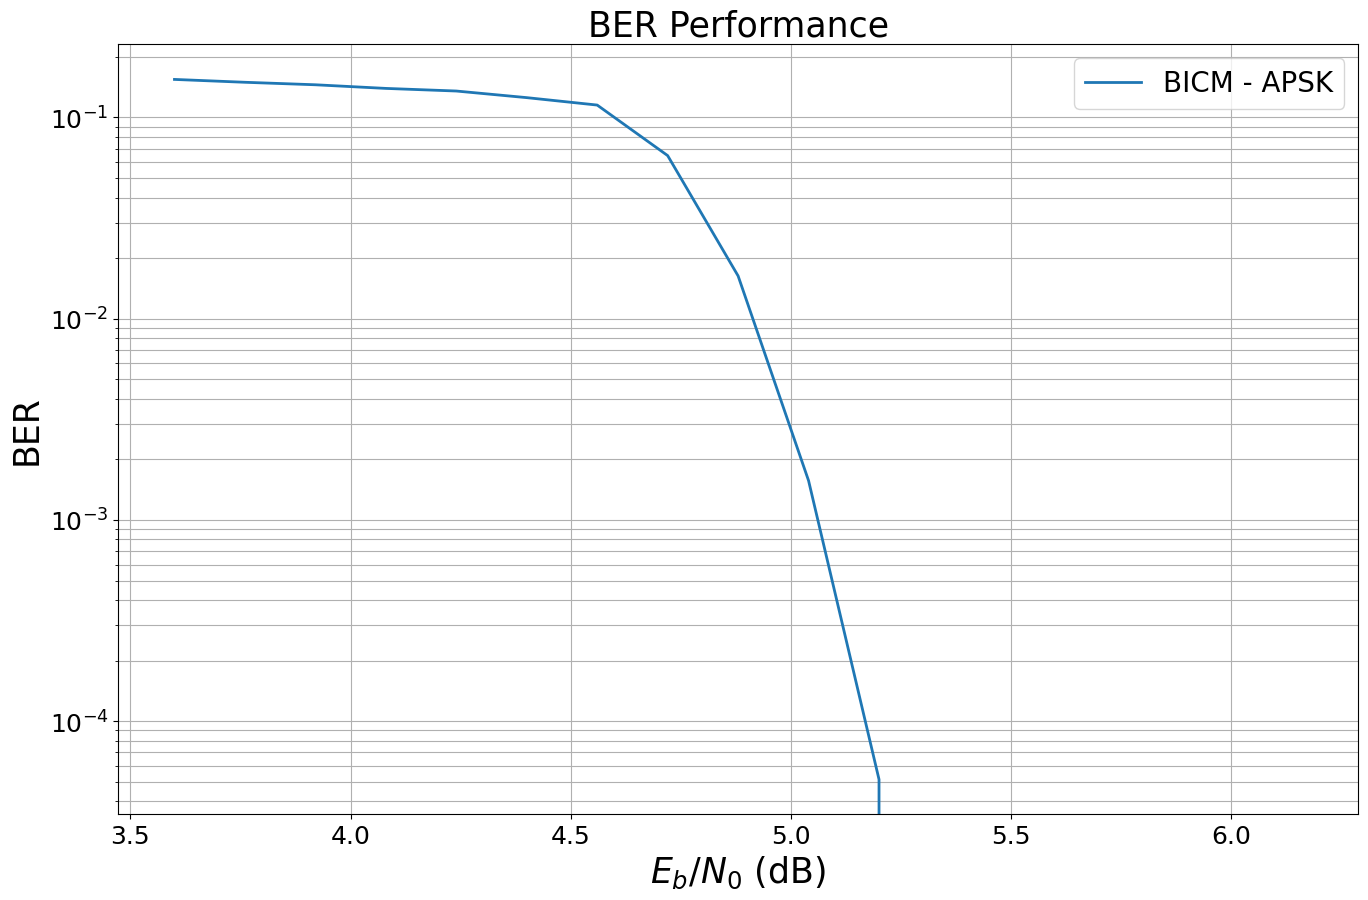

In [8]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_RBF = False
model_bicm = BICM_scheme_awgn(batch_size, num_bp_iter, use_dvb, symbol_points_apsk, perfect_csi, use_RBF)

u, u_hat = model_bicm(tf.constant(batch_size, tf.int32), tf.constant(5, tf.float32))



ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(3.6, 6.2, 0.16),
                          legend="BICM - APSK",
                          max_mc_iter=200,
                          num_target_bit_errors=10000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

In [9]:
bicm_snr = ber_plot_bicm.snr[0]
bicm_ber =  ber_plot_bicm.ber[0]

In [10]:
class BICM_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, use_dvb, symbol_points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition):
        super().__init__() # Must call the Keras model initializer

        self.use_dvb = use_dvb
        self.batch_size = batch_size
        llr_max_value = 120.00

        self.channel = AWGN()
        self.num_bits_per_symbol = 5

        if self.use_dvb:

            r = 8/15
            n_ldpc = 16200
            self.n = n_ldpc
            self.k = int(n_ldpc*r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=21,file_path="ldpccode_short_8_15.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k])

            self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False)
            self.source = BinarySource()

        else:
            self.k = 864
            self.n = 1440

            self.binary_source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            # self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        probabilities = np.ones_like(symbol_points)/(2**self.num_bits_per_symbol)

        power = np.sum(probabilities * np.abs(symbol_points)**2)
        self.normalized_points = symbol_points / np.sqrt(power)

        constellation = Constellation("custom", num_bits_per_symbol=self.num_bits_per_symbol , points = self.normalized_points)

        # mapper and demapper
        self.mapper = Mapper(constellation=constellation)

        if pn_freq == '220':
            fc = 220e9
            pn_var = 0.0108
        elif pn_freq == '120':
            fc = 120e9
            pn_var = 0.0032
        # self.demapper = Demapper("app", constellation=constellation) # APP demapper
        self.demapper = Demapper_optimized("app", constellation=constellation, pn_var=pn_var, condition=condition) # APP demapper

        self.num_symbols = int(self.n/self.num_bits_per_symbol)
        self.use_upsampling_filtering_pn  = use_upsampling_filtering_pn

        if use_upsampling_filtering_pn:
            self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
            self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)

            num_ptrs_blocks = 32
            symbols_per_ptrs_block = 4
            block_size_ptrs = self.num_symbols+ 4*32
            bandwidth = 960e3*4096

            samples = 4*(block_size_ptrs+32)

            self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                          offset = self.rx_filter.length - 1,
                                                     num_symbols=tf.cast(block_size_ptrs, tf.int32))

            path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"

            self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
            self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs\
                                                 , self.ptrs_adder.pilots,batch_size, num_ptrs_blocks, symbols_per_ptrs_block)
            self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
            self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        no = ebnodb2no(ebno_db,
           num_bits_per_symbol=self.num_bits_per_symbol,
           coderate=8/15)

        if self.use_dvb:
            # u, c = next(self.iterator)
            b_stream = tf.cast(self.source([batch_size, self.k]),tf.int32) # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            c = tf.concat([b_stream, p_bits], axis=1)
        else:
            u = self.binary_source([self.batch_size, self.k])
            c = tf.cast(self.encoder(u),tf.uint8)

        # u, c = next(self.iterator)
        c_int = self.interleaver(c)
        x = self.mapper(c_int)

        if self.use_upsampling_filtering_pn:
            ptrs_x_mod = self.ptrs_adder(x)
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, no)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_data_vec = self.pn_compensate(y)
        else:
            y_data_vec = self.channel(x, no)
        ##################################
        # llr_ch = self.demapper(y_data_vec, no) # demapp
        llr_ch = self.demapper(y_data_vec, no, self.normalized_points)
        llr_deint = self.deinterleaver(llr_ch)

        if self.use_dvb:
            llr_u_stream = self.decoder(llr_deint)
            u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
            b_stream_hat = u_stream_hat[:,:self.k]
            return b_stream, b_stream_hat
        else:
            b_stream_hat = self.decoder(llr_deint) # run LDPC decoder
            return u, b_stream_hat


I0000 00:00:1787764867.636184   16989 cuda_dnn.cc:529] Loaded cuDNN version 91400


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      3.6 | 1.8502e-01 | 1.0000e+00 |       31971 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.68 | 1.8304e-01 | 1.0000e+00 |       31630 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.76 | 1.8227e-01 | 1.0000e+00 |       31497 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.84 | 1.7913e-01 | 1.0000e+00 |       30954 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.92 | 1.7841e-01 | 1.0000e+00 |       30829 |      172800 |           20 |          20 |         0.1 |reached target bit errors
      4.0 | 1.7746e-01 | 1.0000e+00 |       30665 |      172800 |          

(<tf.Tensor: shape=(51,), dtype=float32, numpy=
 array([1.8501736e-01, 1.8304399e-01, 1.8227431e-01, 1.7913194e-01,
        1.7840856e-01, 1.7745949e-01, 1.7354167e-01, 1.7245950e-01,
        1.6994213e-01, 1.6927662e-01, 1.6712384e-01, 1.6435185e-01,
        1.6608217e-01, 1.6157408e-01, 1.5729745e-01, 1.5537615e-01,
        1.5519097e-01, 1.5344329e-01, 1.5206598e-01, 1.4773726e-01,
        1.4681134e-01, 1.4370950e-01, 1.3884260e-01, 1.3984375e-01,
        1.3666087e-01, 1.3576968e-01, 1.3094328e-01, 1.3010417e-01,
        1.2724537e-01, 1.2492477e-01, 1.2297454e-01, 1.2016782e-01,
        1.0643519e-01, 9.5729165e-02, 7.4334487e-02, 5.4473381e-02,
        2.7843364e-02, 1.3175926e-02, 3.8384132e-03, 8.0146501e-04,
        2.7786457e-04, 5.1504630e-06, 1.0416667e-06, 1.5046296e-06,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(51,), dtype=float32, numpy=
 array([1.0000000

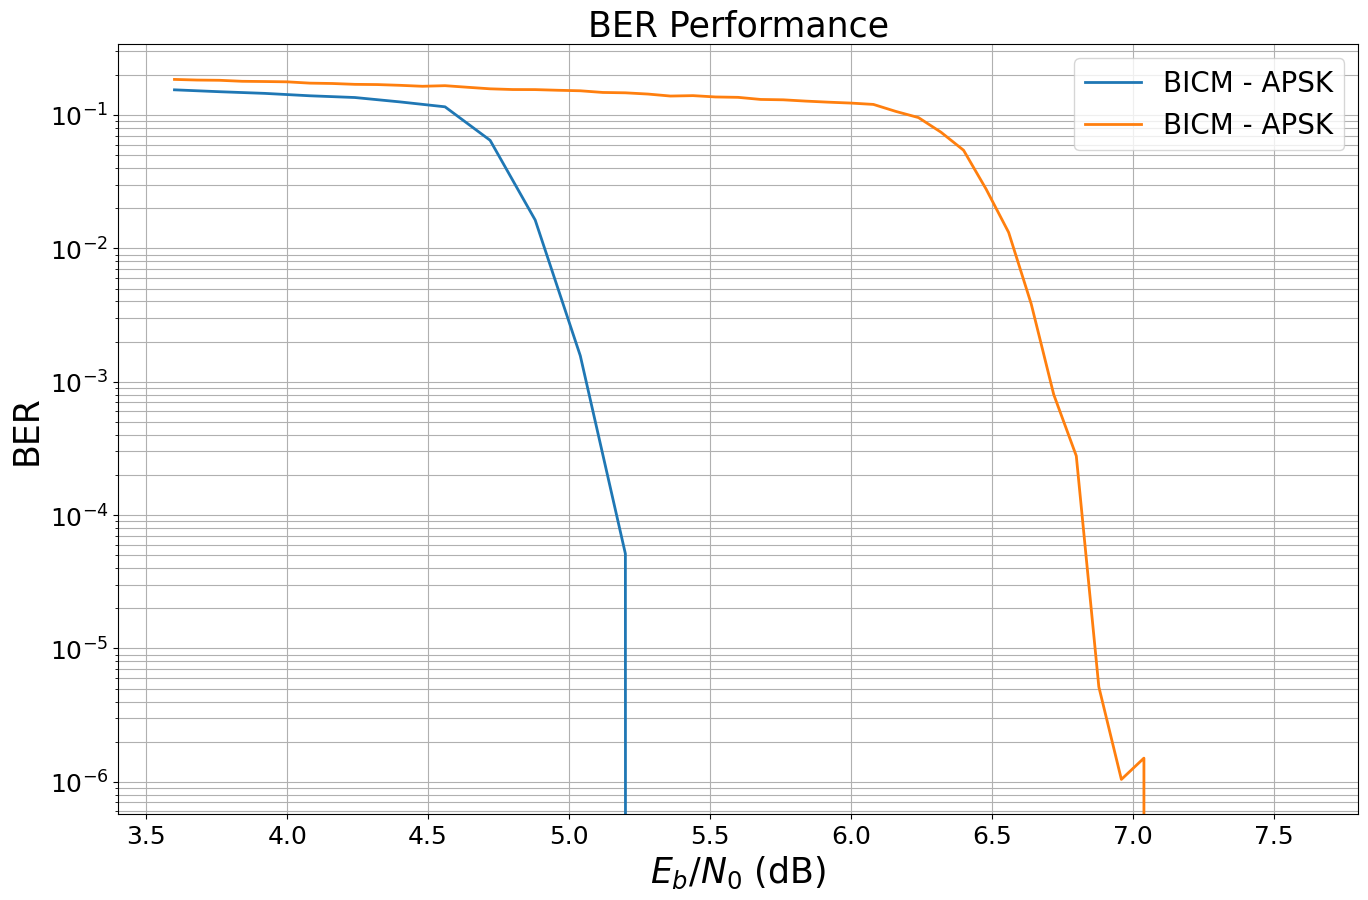

In [11]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
pn_freq = '220' # 220
condition = 'highsnr' # awgn highsnr
model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_apsk, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)

u, u_hat = model_bicm(tf.constant(batch_size, tf.int32), tf.constant(5, tf.float32))

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(3.6, 7.64, 0.08),
                          legend="BICM - APSK",
                          max_mc_iter=200, #200
                          num_target_bit_errors=10000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      3.6 | 1.8024e-01 | 1.0000e+00 |       31146 |      172800 |           20 |          20 |         0.2 |reached target bit errors
     3.68 | 1.7844e-01 | 1.0000e+00 |       30835 |      172800 |           20 |          20 |         0.2 |reached target bit errors
     3.76 | 1.7589e-01 | 1.0000e+00 |       30394 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.84 | 1.7524e-01 | 1.0000e+00 |       30281 |      172800 |           20 |          20 |         0.1 |reached target bit errors
     3.92 | 1.7260e-01 | 1.0000e+00 |       29826 |      172800 |           20 |          20 |         0.1 |reached target bit errors
      4.0 | 1.7120e-01 | 1.0000e+00 |       29584 |      172800 |          

(<tf.Tensor: shape=(51,), dtype=float32, numpy=
 array([1.8024306e-01, 1.7844328e-01, 1.7589121e-01, 1.7523727e-01,
        1.7260417e-01, 1.7120370e-01, 1.7164353e-01, 1.6847222e-01,
        1.6436343e-01, 1.6440393e-01, 1.6166088e-01, 1.6194445e-01,
        1.5875000e-01, 1.5742476e-01, 1.5540509e-01, 1.5109953e-01,
        1.5195023e-01, 1.4752315e-01, 1.4736690e-01, 1.4428240e-01,
        1.4273727e-01, 1.4258102e-01, 1.3910301e-01, 1.3648148e-01,
        1.3469908e-01, 1.3152198e-01, 1.2870370e-01, 1.2619792e-01,
        1.2371528e-01, 1.1695023e-01, 1.1574074e-01, 1.1001158e-01,
        1.0042246e-01, 8.1574075e-02, 3.8434606e-02, 3.3489585e-02,
        8.6541008e-03, 3.3500514e-03, 8.3234126e-04, 2.0089699e-04,
        1.7650462e-06, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(51,), dtype=float32, numpy=
 array([1.       

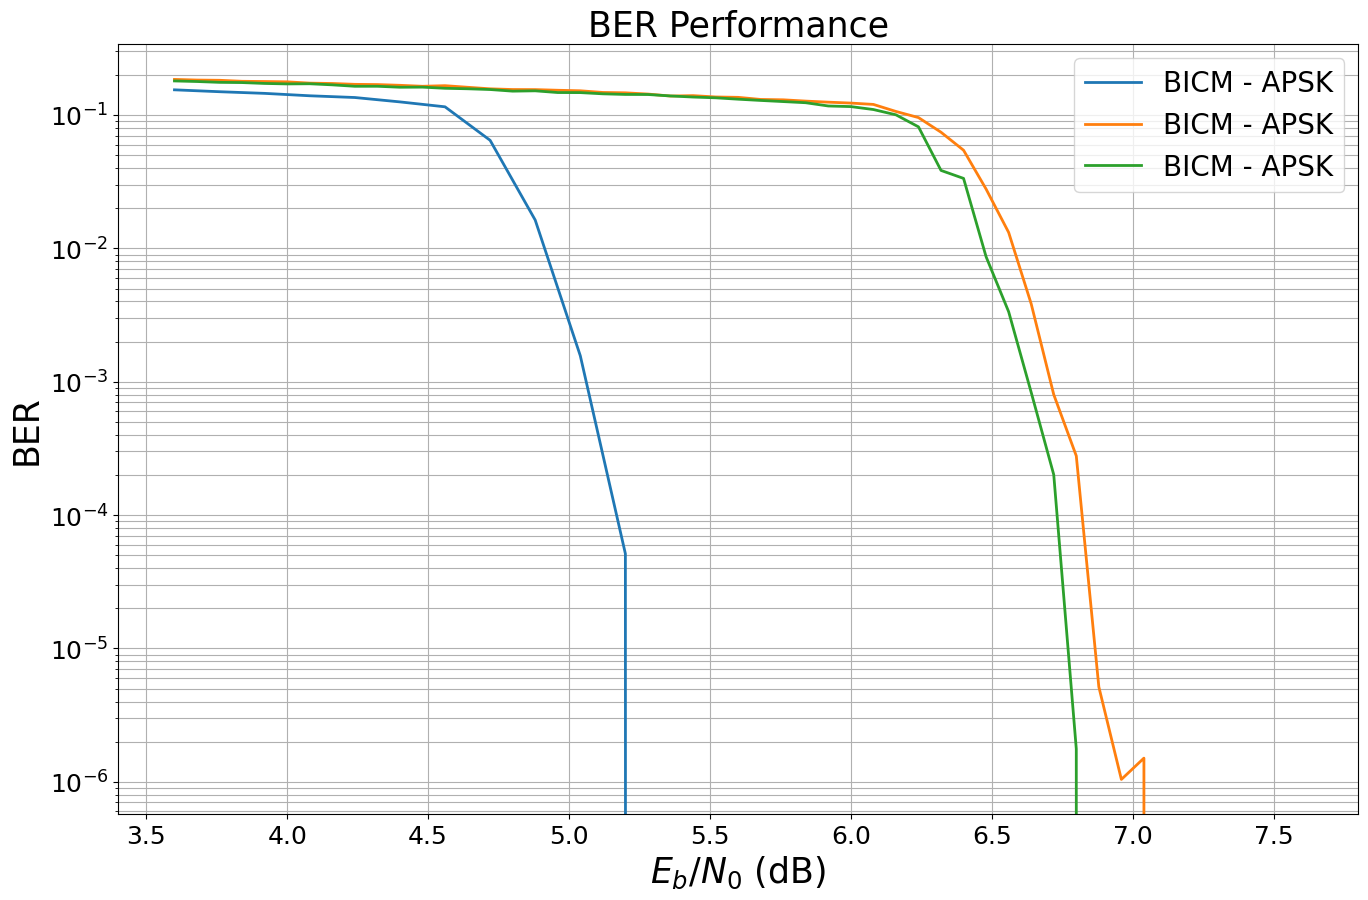

In [12]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
pn_freq = '220' # 220
condition = 'lowpn' # awgn highsnr
model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_apsk, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)

u, u_hat = model_bicm(tf.constant(batch_size, tf.int32), tf.constant(5, tf.float32))

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(3.6, 7.64, 0.08),
                          legend="BICM - APSK",
                          max_mc_iter=200, #200
                          num_target_bit_errors=10000,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

In [13]:
bicm_snr_highsnr = ber_plot_bicm.snr[1]
bicm_ber_highsnr =  ber_plot_bicm.ber[1]

bicm_snr_lowpn = ber_plot_bicm.snr[2]
bicm_ber_lowpn =  ber_plot_bicm.ber[2]

In [14]:
np.savez("bicm_ldpc_correction.npz",
         bicm_snr_=bicm_snr,
         bicm_ber_=bicm_ber,
         bicm_snr_lowpn_=bicm_snr_lowpn,
         bicm_ber_lowpn_=bicm_ber_lowpn,
         bicm_snr_highsnr_=bicm_snr_highsnr,
         bicm_ber_highsnr_=bicm_ber_highsnr)

In [20]:
ber_plot_bicm.ber

[<tf.Tensor: shape=(17,), dtype=float32, numpy=
 array([1.5410301e-01, 1.4986111e-01, 1.4532408e-01, 1.4023727e-01,
        1.3324653e-01, 1.1903935e-01, 1.0192709e-01, 4.3703705e-02,
        1.4643518e-02, 9.5068687e-04, 7.3321760e-05, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(51,), dtype=float32, numpy=
 array([ 1.78599536e-01,  1.77818283e-01,  1.75978005e-01,  1.75277784e-01,
         1.72418982e-01,  1.69490740e-01,  1.69155091e-01,  1.66672453e-01,
         1.64357632e-01,  1.61684021e-01,  1.58877313e-01,  1.57418981e-01,
         1.55486107e-01,  1.52928248e-01,  1.51521996e-01,  1.47390053e-01,
         1.47366896e-01,  1.44901618e-01,  1.43072918e-01,  1.40648142e-01,
         1.37708336e-01,  1.36649311e-01,  1.31140053e-01,  1.29450232e-01,
         1.29971072e-01,  1.25949070e-01,  1.22505784e-01,  1.18680559e-01,
         1.20266207e-01,  1.14652775e-01,  1.13559030e-01, 